In [15]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import os
import sys
sys.path.append('../scripts')
import landcover_definitions as lc

from make_priors_chesapeake import condense_cc7_to_cc5_cooccurrance

In [2]:
pip install rasterio

  Using cached affine-3.0.1-py3-none-any.whl.metadata (4.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 111.2 MB/s  0:00:00eta 0:00:01
Using cached affine-3.0.1-py3-none-any.whl (10 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rasterio]1/2 [rasterio]
Note: you may need to restart the kernel to use updated packages.


In [13]:
lcmap_codes = [1, 2, 3, 4, 5, 6, 7, 8]
lcmap_names = ["Developed", "Cropland", "Grass/Shrub", "Tree Cover",
               "Water", "Wetland", "Ice/Snow", "Barren"]

targets = ["Developed", "Cropland", "Grass/Shrub", "Tree Cover",
               "Water", "Wetland", "Ice/Snow", "Barren"]  

# rows = targets, cols = LCMAP classes
## first pass just use basic for the same classes where it is 90% the same class but then some fuzziness for the 10%
recipes = {
    #                 develop  crop  grass  tree  water  wetland  ice  barren
    "Developed":      [0.90,  0.05,  0.00,  0.00,  0.00,  0.00,  0.00,  0.05],
    "Cropland":       [0.00,  0.90,  0.05,  0.05,  0.00,  0.00,  0.00,  0.00],
    "Grass/Shrub":    [0.00,  0.05,  0.90,  0.05,  0.00,  0.00,  0.00,  0.00],
    "Tree Cover":     [0.00,  0.05,  0.50,  0.90,  0.00,  0.00,  0.00,  0.00],
    "Water":          [0.00,  0.00,  0.00,  0.00,  0.90,  0.05,  0.00,  0.05],
    "Wetland":        [0.00,  0.00,  0.05,  0.00,  0.05,  0.90,  0.00,  0.00],
    "Ice/Snow":       [0.00,  0.05,  0.00,  0.00,  0.00,  0.00,  0.90,  0.05],
    "Barren":         [0.00,  0.05,  0.05,  0.00,  0.00,  0.00,  0.00,  0.90],
}

LCMAP_CLASS_COLORS = {
    0: (0, 0, 0, 0),
    1: (255, 50, 50, 255),     # Developed
    2: (190, 140, 90, 255),    # Cropland
    3: (230, 240, 210, 255),   # Grass/Shrub
    4: (28, 99, 48, 255),      # Tree Cover
    5: (0, 112, 255, 255),     # Water
    6: (179, 217, 255, 255),   # Wetland
    7: (255, 255, 255, 255),   # Ice/Snow
    8: (179, 174, 163, 255),   # Barren
}

LCMAP_CLASS_COLORS_NO_0 = {
    0: (255, 50, 50, 255),     # Developed
    1: (190, 140, 90, 255),    # Cropland
    2: (230, 240, 210, 255),   # Grass/Shrub
    3: (28, 99, 48, 255),      # Tree Cover
    4: (0, 112, 255, 255),     # Water
    5: (179, 217, 255, 255),   # Wetland
    6: (255, 255, 255, 255),   # Ice/Snow
    7: (179, 174, 163, 255),   # Barren
}

def get_colors(class_colors):
    return np.array([class_colors[c] for c in class_colors.keys()]) / 255.0


def vis_lc(r, lc_type, renorm=True, reindexed=True):
    colors = get_colors(lc_type)
    
    sparse = r.shape[0] != len(colors)
    colors_cycle  = range(0, len(colors))
   #    colors_cycle  = range(len(colors))
    if sparse:
        z = np.zeros((3,) + r.shape)
        s = r
        for c in colors_cycle:
            for ch in range(3):
                z[ch] += colors[c][ch] * (s == c).astype(float)
        
    else:
        z = np.zeros((3,) + r.shape[1:])
        if renorm: s = r / r.sum(0)
        else: s = r
        for c in colors_cycle:
            for ch in range(3):
                z[ch] += colors[c][ch] * s[c] 
    return z

(8, 8000, 5000)
(8, 8)


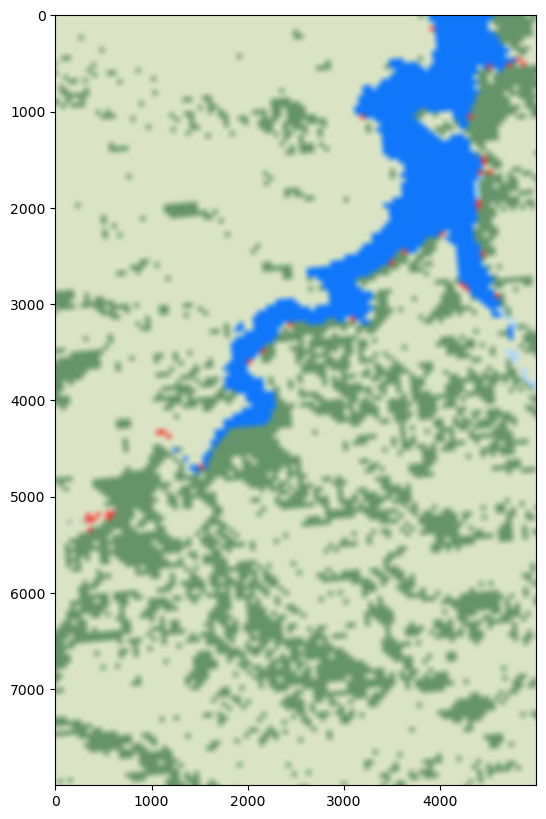

In [20]:
prior_fp = '/data-store/iplant/home/emilynagamoto/NAIP_LCMAP/hayman_prior_from_cooccurrences_101_31_no_osm_no_buildings.tif'
M = pd.DataFrame(recipes, index=targets)[lcmap_names]   
M.columns = lcmap_codes 
cooc_matrix_file1 = M.to_numpy()

with rasterio.open(prior_fp) as f:
        prior = f.read()
        print(prior.shape)           # (7, 2000, 2000)
        print(cooc_matrix_file1.shape)     # rows = output classes, including the nodata slot
        fig, ax = plt.subplots(figsize=(10,10))
        ax.imshow(vis_lc(prior, lc_type=LCMAP_CLASS_COLORS_NO_0).T.swapaxes(0,1))


In [15]:
CC_data_dir = "/home/esther/torchgeo_data/cvpr_chesapeake_landcover"

def unique_tile_ids_from_dir(data_dir_this):
    """Get tile ids from a provided data dir."""
    return np.unique([x[2:17] for x in os.listdir(data_dir_this)])


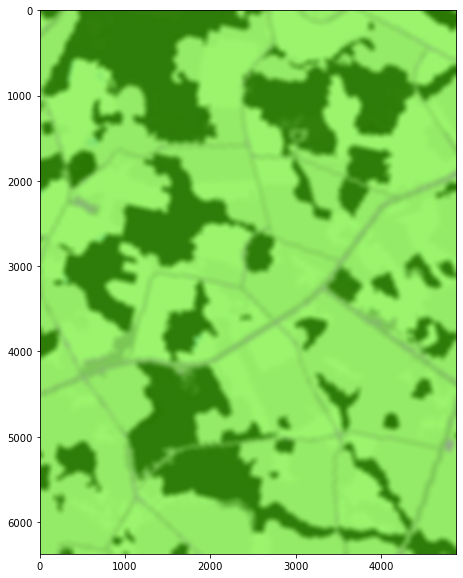

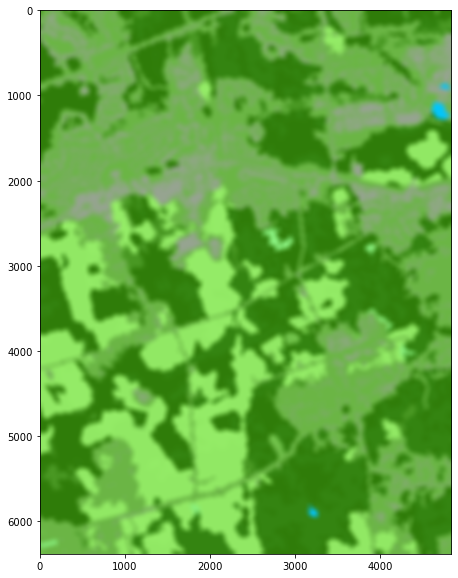

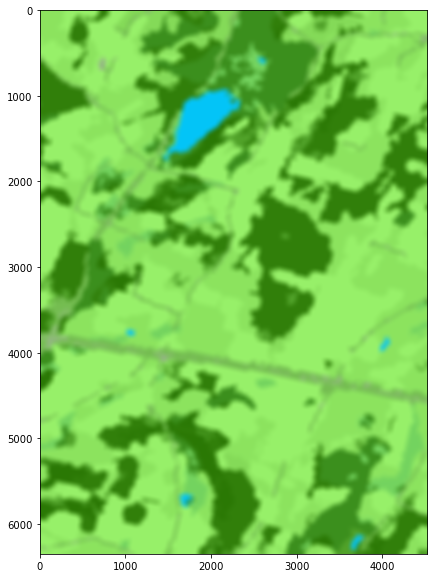

In [33]:
states_to_vis = ["de", "md", "ny"]#, "pa", "va", "wv"]
years = [2013, 2013, 2013]#, 2013, 2014, 2014]
set_to_viz = 'val'
    
idxs_viz = [1]
cooccurrence_mapping_matrices = {}
for state, year in zip(states_to_vis,years):
    
    dir_this_set = f'{CC_data_dir}/{state}_1m_{year}_extended-debuffered-{set_to_viz}_tiles'
    tiles_this_set = unique_tile_ids_from_dir(dir_this_set)
        
    for idx_viz in idxs_viz:
         
        prior_fp = f'{dir_this_set}/m_{tiles_this_set[idx_viz]}_prior_from_cooccurrences_101_31_no_osm_no_buildings.tif'
    
        with rasterio.open(prior_fp) as f:
            prior = f.read()
            
        fig, ax = plt.subplots(figsize=(10,10))
        ax.imshow(lc.vis_lc(prior, lc_type='chesapeake_4_no_zeros').T.swapaxes(0,1))
